Titanic Dataset:
        Age      Fare    Pclass     SibSp     Parch  Survived
0 -1.940913  0.071408  1.691954 -4.181512  0.086355         1
1 -0.626351 -2.077537  0.897010 -0.822142 -0.168507         0
2 -1.476548 -0.461293  0.664429  1.306103  0.435675         0
3 -4.966780 -2.730796  0.711024 -5.170028 -0.836628         1
4  0.467695  0.863693  2.000070 -2.864411  1.669229         1

Dataset Shape: (500, 6)

Dataset saved successfully!

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Age       500 non-null    float64
 1   Fare      500 non-null    float64
 2   Pclass    500 non-null    float64
 3   SibSp     500 non-null    float64
 4   Parch     500 non-null    float64
 5   Survived  500 non-null    int64  
dtypes: float64(5), int64(1)
memory usage: 23.6 KB

Statistical Summary:
              Age        Fare      Pclass       SibSp    

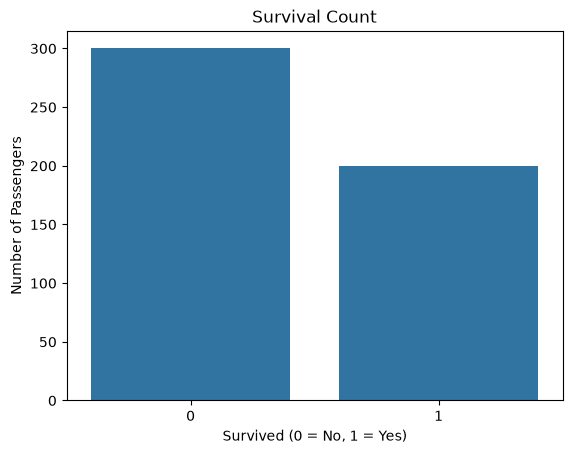

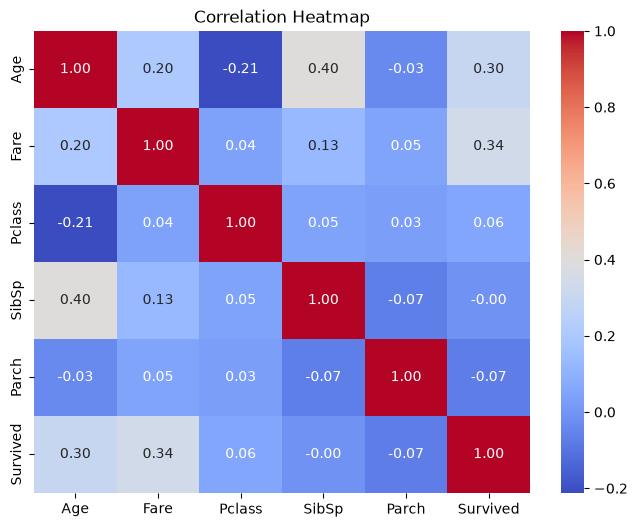


Training Data: (400, 5)
Testing Data: (100, 5)

Model Training Completed!

Actual vs Predicted:
   Actual Survival  Predicted Survival
0                0                   0
1                1                   1
2                0                   0
3                0                   0
4                1                   1
5                0                   0
6                1                   1
7                0                   0
8                0                   0
9                0                   0

Model Evaluation:
Accuracy: 0.71
Precision: 0.6571428571428571
Recall: 0.575
F1 Score: 0.6133333333333333

Confusion Matrix:
[[48 12]
 [17 23]]


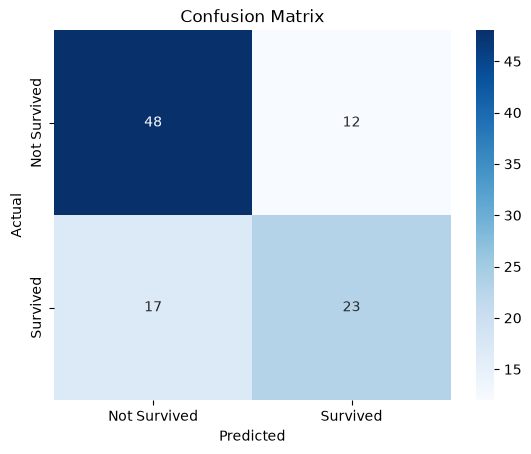


Classification Report:
              precision    recall  f1-score   support

           0       0.74      0.80      0.77        60
           1       0.66      0.57      0.61        40

    accuracy                           0.71       100
   macro avg       0.70      0.69      0.69       100
weighted avg       0.71      0.71      0.71       100


Passenger is predicted to SURVIVE.


In [1]:
# 1. Import Libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score
)


# 2. Generate Synthetic Titanic-like Dataset

X, y = make_classification(
    n_samples=500,
    n_features=5,
    n_informative=4,
    n_redundant=0,
    n_classes=2,
    weights=[0.6, 0.4],
    random_state=42
)


# 3. Create DataFrame

df = pd.DataFrame(
    X,
    columns=["Age", "Fare", "Pclass", "SibSp", "Parch"]
)

df["Survived"] = y

print("Titanic Dataset:")
print(df.head())

print("\nDataset Shape:", df.shape)


# 4. Save Dataset as CSV

df.to_csv("titanic_dataset.csv", index=False)

print("\nDataset saved successfully!")


# 5. Analyze Dataset

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
print(df.describe())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nSurvival Count:")
print(df["Survived"].value_counts())


# 6. Visualize Survival Count

sns.countplot(x="Survived", data=df)

plt.title("Survival Count")
plt.xlabel("Survived (0 = No, 1 = Yes)")
plt.ylabel("Number of Passengers")
plt.show()


# 7. Correlation Analysis

correlation = df.corr()

plt.figure(figsize=(8, 6))
sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f")

plt.title("Correlation Heatmap")
plt.show()


# 8. Separate Features and Target

X = df.drop("Survived", axis=1)
y = df["Survived"]


# 9. Split Dataset

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining Data:", X_train.shape)
print("Testing Data:", X_test.shape)


# 10. Create Logistic Regression Model

model = LogisticRegression(max_iter=1000)


# 11. Train Model

model.fit(X_train, y_train)

print("\nModel Training Completed!")


# 12. Predict Survival

y_pred = model.predict(X_test)


# 13. Compare Actual and Predicted Values

comparison = pd.DataFrame({
    "Actual Survival": y_test.values,
    "Predicted Survival": y_pred
})

print("\nActual vs Predicted:")
print(comparison.head(10))


# 14. Evaluate Model

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("\nModel Evaluation:")
print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)


# 15. Confusion Matrix

cm = confusion_matrix(y_test, y_pred)

print("\nConfusion Matrix:")
print(cm)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Not Survived", "Survived"],
    yticklabels=["Not Survived", "Survived"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()


# 16. Classification Report

print("\nClassification Report:")
print(classification_report(y_test, y_pred))


# 17. Predict Survival for a New Passenger

new_passenger = pd.DataFrame({
    "Age": [25],
    "Fare": [50],
    "Pclass": [2],
    "SibSp": [1],
    "Parch": [0]
})

prediction = model.predict(new_passenger)

if prediction[0] == 1:
    print("\nPassenger is predicted to SURVIVE.")
else:
    print("\nPassenger is predicted to NOT SURVIVE.")